# Modelado de tópicos con BERTopic: HDBSCAN frente a K-means

Bloque 2 (modelado de tópicos con BERTopic). Machine Learning 2026/27, competición de Kaggle *Contradictory, My Dear Watson*.

Este notebook calcula y guarda en caché los embeddings de las premisas, ajusta dos pipelines de BERTopic que solo se diferencian en el algoritmo de clustering (HDBSCAN o K-means), los compara e interpreta, asigna un tópico a cada fila de train y val, y estudia la relación de los tópicos con las clases NLI y con el idioma.

Datos necesarios:
- `data/train.csv`, de la competición (https://www.kaggle.com/competitions/contradictory-my-dear-watson/data);
- la partición del Bloque 1: `artifacts/splits/train.csv` y `val.csv`;
- la traducción del Bloque 1: `artifacts/translations/train_gemma3_4b.csv`.

El modelo de embeddings se descarga de HuggingFace la primera vez que se ejecuta.

Para ejecutarlo, desde la raíz del repo y con el entorno `.venv`:

```
.venv\Scripts\python -m jupyter nbconvert --to notebook --execute --inplace topic_modeling.ipynb
```

Orden de ejecución del Bloque 2: `topic_eda.ipynb` → `topic_modeling.ipynb` → `topic_experiment.ipynb`.
Semilla: `SEED = 42` en todo. Las versiones de los paquetes se imprimen en la primera celda de código.

In [1]:
import sys, platform, importlib.metadata as md
SEED = 42
def versiones(paquetes):
    filas = [("python", platform.python_version())]
    for p in paquetes:
        try:
            filas.append((p, md.version(p)))
        except md.PackageNotFoundError:
            filas.append((p, "no instalado"))
    return filas

import time, re, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib as mpl
import matplotlib.pyplot as plt
# Paleta categórica fija (mismo orden en todos los notebooks del Bloque 2).
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#8a5cd1", "#c23b3b"]
GRIS, GRIS_CLARO = "#8f8e88", "#d9d8d3"
COLOR_CLASE = {"entailment": PALETA[0], "neutral": PALETA[1], "contradiction": PALETA[2]}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

pd.set_option("display.max_colwidth", 110)
PAQUETES = ["bertopic", "umap-learn", "hdbscan", "sentence-transformers", "torch", "scikit-learn", "scipy", "numpy", "pandas", "matplotlib"]
for p, v in versiones(PAQUETES):
    print(f"{p:22s} {v}")
np.random.seed(SEED)

python                 3.11.9
bertopic               0.17.4
umap-learn             0.6.0
hdbscan                0.8.44
sentence-transformers  6.3.0
torch                  2.15.0
scikit-learn           1.9.1
scipy                  1.17.1
numpy                  2.4.6
pandas                 3.1.1
matplotlib             3.11.2


## 0. Configuración

Todos los parámetros que se pueden cambiar están en esta celda.

| Parámetro | Valor | Por qué |
|---|---|---|
| `TEXT_COL` | `premise_translated` | Corpus traducido al inglés, como el mejor modelo con n-gramas del Bloque 1. Con `"premise"` se usa el texto original. |
| Embeddings | `paraphrase-multilingual-MiniLM-L12-v2` (384 dim.) | El mismo modelo que usa el Bloque 1. Si existe `.local/minilm-checkpoint/` se usa ese checkpoint local. |
| UMAP | `n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42` | Igual en las dos configuraciones, para que solo cambie el clustering. |
| A: HDBSCAN | `min_cluster_size ∈ {15, 30, 50}`, `prediction_data=True` | Se prueba una rejilla pequeña. `prediction_data=True` permite hacer `transform` con premisas nuevas. |
| B: K-means | `n_clusters=k`, `n_init=10`, `random_state=42` | k cercana al número de tópicos de A, con silhouette como control. |
| c-TF-IDF | `CountVectorizer(stop_words=inglés ∪ {uh, um, yeah, oh}, ngram_range=(1,2), min_df=2)` | Solo describe los tópicos; no influye en cómo se forman. |

In [2]:
TEXT_COL = "premise_translated"
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
LOCAL_CKPT = Path(".local/minilm-checkpoint")
UMAP_PARAMS = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
MCS_GRID = [15, 30, 50]
OPT = {"dtype": {"id": str}, "keep_default_na": False}
CACHE = Path("artifacts/embeddings/topics"); CACHE.mkdir(parents=True, exist_ok=True)
OUT = Path("results_topics"); OUT.mkdir(exist_ok=True)
LABELS = {0: "entailment", 1: "neutral", 2: "contradiction"}
TIEMPOS = {}
def corto(s, n):
    return s if len(s) <= n else s[: n - 1] + "…"

## 1. Embeddings en caché

### 1.1. Documentos: premisas sin repetir

Como se justificó en `topic_eda.ipynb`, un documento es una premisa distinta, deduplicada por su texto original (8.209 documentos). El texto que se embebe es `TEXT_COL`, la primera traducción de esa premisa. Para cada documento se guarda si aparece en train (`in_train`), en val (`in_val`) o en ambos.

In [3]:
df = pd.read_csv("artifacts/translations/train_gemma3_4b.csv", **OPT)
parts = pd.concat([pd.read_csv("artifacts/splits/train.csv", **OPT)[["id"]].assign(part="train"),
                   pd.read_csv("artifacts/splits/val.csv", **OPT)[["id"]].assign(part="val")])
df = df.merge(parts, on="id", validate="one_to_one")
g = df.groupby("premise", sort=False)
premises = pd.DataFrame({
    "premise_original": g.size().index,
    "text": g[TEXT_COL].first().values,
    "lang_abv": g["lang_abv"].first().values,
    "in_train": g["part"].apply(lambda s: s.eq("train").any()).values,
    "in_val": g["part"].apply(lambda s: s.eq("val").any()).values,
})
def frac_no_latina(s):
    letras = [c for c in s if c.isalpha()]
    return sum(ord(c) > 591 for c in letras) / max(1, len(letras))
# Texto legible en inglés: premisa inglesa original o traducción real (no copia del original).
premises["texto_ingles"] = premises.lang_abv.eq("en") | (premises.text.ne(premises.premise_original)
                                                          & premises.text.map(frac_no_latina).lt(0.3))
print(len(premises), "documentos |", int(premises.in_train.sum()), "en train |", int(premises.in_val.sum()), "en val |",
      int((premises.in_train & premises.in_val).sum()), "en ambos |", int((premises.in_val & ~premises.in_train).sum()), "solo en val")

8209 documentos | 7051 en train | 2250 en val | 1092 en ambos | 1158 solo en val


### 1.2. Modelo de embeddings y posible solapamiento con la competición

- **Modelo:** `paraphrase-multilingual-MiniLM-L12-v2` (sentence-transformers). Es un transformer de 12 capas que produce un vector de 384 dimensiones por frase. Se obtuvo por *destilación multilingüe* (Reimers y Gurevych, 2020): un modelo "profesor" inglés de paráfrasis enseña a un "alumno" multilingüe a producir el mismo vector para una frase y su traducción. Por eso una frase y su traducción quedan cerca en el espacio vectorial, aunque estén en idiomas distintos.
- **Entrenamiento previo con NLI:** los datos de entrenamiento de los modelos `paraphrase-*` incluyen AllNLI (SNLI + MultiNLI). Las premisas de esta competición vienen muy probablemente de XNLI, que es MultiNLI traducido a 15 idiomas, y se ven sus géneros (informes del gobierno, guías de viaje, ficción, conversaciones telefónicas, Slate, el informe del 11-S). Por tanto, es posible que el modelo haya visto algunas de estas frases inglesas durante su preentrenamiento.
- **¿Afecta?** Para los tópicos, apenas: BERTopic no usa etiquetas y solo necesita que frases parecidas tengan vectores parecidos. Para un clasificador que use estos embeddings (el MiniLM del Bloque 1) sí podría inflar un poco el resultado. Se documenta como limitación.
- **Sin fuga:** calcular embeddings de val no es una fuga, porque el modelo ya viene entrenado y no aprende nada de nuestros datos. Lo que se ajusta (UMAP, clustering, c-TF-IDF) se ajusta solo con train.
- **Qué entrenamos nosotros y qué no:** el modelo de embeddings no se entrena ni se ajusta: se usa tal cual, preentrenado. Lo que entrenamos con nuestras premisas de train es UMAP, HDBSCAN o K-means, el vocabulario del c-TF-IDF y, en el experimento, el one-hot y los clasificadores (CatBoost y Naive Bayes, junto con el TF-IDF y la selección chi² del Bloque 1).
- `normalize_embeddings=True` deja cada vector con norma 1, de modo que el producto escalar es la similitud coseno.

In [4]:
def embeddings_en_cache(columna, fichero):
    ruta = CACHE / fichero
    textos = premises[columna].tolist()
    if ruta.exists() and (CACHE / "premises.csv").exists():
        prev = pd.read_csv(CACHE / "premises.csv", keep_default_na=False)
        emb = np.load(ruta)
        if len(prev) == len(premises) and prev.premise_original.tolist() == premises.premise_original.tolist() and emb.shape[0] == len(textos):
            print(f"{fichero}: cargado de caché {emb.shape}")
            return emb
    from sentence_transformers import SentenceTransformer
    nombre = str(LOCAL_CKPT) if LOCAL_CKPT.exists() else MODEL_NAME
    modelo = SentenceTransformer(nombre, device="cpu")
    t0 = time.perf_counter()
    emb = modelo.encode(textos, batch_size=64, normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
    TIEMPOS[f"embeddings_{columna}"] = round(time.perf_counter() - t0, 1)
    np.save(ruta, emb)
    print(f"{fichero}: calculado en {TIEMPOS[f'embeddings_{columna}']} s {emb.shape}")
    return emb

emb = embeddings_en_cache("text", "emb_premises.npy")                         # corpus de tópicos (TEXT_COL)
emb_orig = embeddings_en_cache("premise_original", "emb_premises_original.npy")  # solo para el control de idioma (sección 6)
premises[["premise_original", "text", "lang_abv", "in_train", "in_val"]].to_csv(CACHE / "premises.csv", index=False)
print("Normas (deben ser 1):", np.round(np.linalg.norm(emb[:3], axis=1), 4))
print("Tiempo medido en la primera ejecución (CPU): ~105 s por cada conjunto de 8.209 premisas.")

emb_premises.npy: cargado de caché (8209, 384)
emb_premises_original.npy: cargado de caché (8209, 384)
Normas (deben ser 1): [1. 1. 1.]
Tiempo medido en la primera ejecución (CPU): ~105 s por cada conjunto de 8.209 premisas.


## 2. Qué hace BERTopic, paso a paso

1. **Embeddings:** cada premisa se convierte en un vector de 384 números (sección 1). Frases con significado parecido tienen vectores cercanos.
2. **UMAP (reducción de dimensión):** comprime los 384 números a 5, intentando conservar qué documentos son vecinos. Se hace porque los algoritmos de clustering funcionan mal en dimensiones muy altas, donde todas las distancias se parecen. `metric="cosine"` porque los embeddings se comparan por ángulo. `min_dist=0.0` permite que los puntos parecidos se apiñen, lo que facilita encontrar grupos. Es igual en A y en B.
3. **Clustering:** agrupa los puntos 5-D. Este es el único paso que cambia entre las dos configuraciones:
   - **A, HDBSCAN:** busca zonas densas. No hay que decirle cuántos grupos hay, y los puntos que no caen en una zona densa se marcan como outliers (tópico −1). `min_cluster_size` es el tamaño mínimo de un grupo.
   - **B, K-means:** hay que fijar k. Coloca k centros y asigna cada documento al más cercano, así que no hay outliers, aunque el documento no encaje bien en ningún grupo.
4. **c-TF-IDF (representación):** une todos los documentos de un tópico en uno solo y calcula TF-IDF *por clase*: qué palabras son frecuentes en ese tópico y raras en los demás. Así se obtienen las palabras que describen cada tópico. Solo describe; no cambia los grupos.

Todo se ajusta solo con las 7.051 premisas de train. Las premisas que solo están en val reciben su tópico con `transform` (sección 5).

In [5]:
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import silhouette_score, normalized_mutual_info_score as NMI
from bertopic import BERTopic

STOP = sorted(ENGLISH_STOP_WORDS | {"uh", "um", "yeah", "oh"})
def nuevo_bertopic(clustering):
    return BERTopic(embedding_model=None, umap_model=UMAP(**UMAP_PARAMS), hdbscan_model=clustering,
                    vectorizer_model=CountVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=2),
                    calculate_probabilities=False, verbose=False)

tr = premises[premises.in_train].reset_index(drop=True)
E_tr = emb[premises.in_train.values]
docs_tr, lang_tr = tr.text.tolist(), tr.lang_abv.values

def resumen(nombre, topics, modelo, segundos):
    t = np.asarray(topics); validos = t[t != -1]
    tam = pd.Series(validos).value_counts()
    palabras = [w for k in tam.index for w, _ in modelo.get_topic(k)[:10]]
    return {"configuracion": nombre, "n_topicos": int(tam.size), "pct_outliers": round(100 * np.mean(t == -1), 1),
            "tam_max": int(tam.max()), "tam_mediana": float(tam.median()), "tam_min": int(tam.min()),
            "diversidad_top10": round(len(set(palabras)) / len(palabras), 3),
            "NMI_idioma": round(NMI(lang_tr, t), 3),
            "NMI_idioma_sin_outliers": round(NMI(lang_tr[t != -1], validos), 3), "segundos": round(segundos, 1)}

## 3. Configuración A: HDBSCAN (rejilla pequeña de `min_cluster_size`)

Se prueban 3 valores, con todo lo demás igual. Las métricas son:
- **número de tópicos** y % de outliers;
- **tamaño** máximo, mediano y mínimo de los tópicos;
- **diversidad**: palabras distintas entre las top-10 de todos los tópicos dividido por el total. Vale 1 si ningún tópico repite palabras con otro;
- **NMI con el idioma**: información mutua normalizada entre el tópico y `lang_abv`. Vale 0 si el tópico no dice nada del idioma y 1 si cada tópico es un idioma;
- **tiempo** de ajuste (incluye UMAP).

In [6]:
modelos_hdb, filas = {}, []
for mcs in MCS_GRID:
    t0 = time.perf_counter()
    m = nuevo_bertopic(HDBSCAN(min_cluster_size=mcs, prediction_data=True))
    topics, _ = m.fit_transform(docs_tr, E_tr)
    seg = time.perf_counter() - t0
    modelos_hdb[mcs] = (m, np.asarray(topics))
    filas.append(resumen(f"A · HDBSCAN mcs={mcs}", topics, m, seg))
rejilla_hdb = pd.DataFrame(filas); display(rejilla_hdb)

,configuracion,n_topicos,pct_outliers,tam_max,tam_mediana,tam_min,diversidad_top10,NMI_idioma,NMI_idioma_sin_outliers,segundos
0,A · HDBSCAN mcs=15,55,38.2,788,42.0,16,0.940,0.048,0.069,42.4
1,A · HDBSCAN mcs=30,20,30.9,1762,107.0,34,0.895,0.026,0.037,8.9
2,A · HDBSCAN mcs=50,19,44.8,851,169.0,53,0.921,0.027,0.043,9.1


Elección: `min_cluster_size = 30`.

- Con 15 salen ~55 tópicos muy pequeños (mediana ~42 premisas), demasiados para interpretarlos y para usarlos como features con pocos ejemplos por categoría, y hay un 38 % de outliers.
- Con 50 los tópicos son muy limpios (el bloque de informes del gobierno se separa en 4 temas), pero casi la mitad de las premisas (45 %) se queda sin tópico.
- Con 30 hay ~20 tópicos (un número interpretable) y el menor % de outliers (31 %). Su punto débil es un tópico grande (~25 % de los documentos) que reúne todos los informes oficiales (servicios legales, programas federales, costes). Se interpreta como el *género* "gobierno" de MultiNLI.

Se usa el modelo ya ajustado de la rejilla (no se vuelve a ajustar).

In [7]:
MCS = 30
tm_hdb, top_hdb = modelos_hdb[MCS]
reducido = tm_hdb.umap_model.embedding_       # proyección UMAP 5-D de train (idéntica en A y B: misma semilla)
print("Tópicos:", len(set(top_hdb) - {-1}), "| outliers:", int((top_hdb == -1).sum()))

Tópicos: 20 | outliers: 2182


## 4. Configuración B: K-means

K-means necesita k. Se calcula la silhouette (−1 a 1; cuanto más alta, mejor separados están los grupos) sobre la misma proyección UMAP 5-D para unos pocos valores de k, como control.

In [8]:
assert np.allclose(UMAP(**UMAP_PARAMS).fit(E_tr).embedding_[:50], reducido[:50]), "UMAP no es reproducible"
sil = []
for k in [10, 15, 20, 25, 30, 40]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(reducido)
    sil.append({"k": k, "silhouette": round(silhouette_score(reducido, lab), 3), "NMI_idioma": round(NMI(lang_tr, lab), 3)})
sil = pd.DataFrame(sil); display(sil)

,k,silhouette,NMI_idioma
0,10,0.343,0.015
1,15,0.364,0.019
2,20,0.347,0.021
3,25,0.355,0.025
4,30,0.354,0.026
5,40,0.365,0.031


Elección: k = 20. La silhouette es casi plana entre k=10 y k=40 (todas entre 0,33 y 0,37), así que no señala ningún k claramente mejor. Por eso se usa el criterio de comparabilidad: k = 20, el mismo número de tópicos que A. Así las dos configuraciones describen el corpus con la misma "resolución" y las diferencias se deben a cómo agrupa cada algoritmo, no al número de grupos.

In [9]:
K = int(len(set(top_hdb) - {-1}))
t0 = time.perf_counter()
tm_km = nuevo_bertopic(KMeans(n_clusters=K, n_init=10, random_state=SEED))
top_km = np.asarray(tm_km.fit_transform(docs_tr, E_tr)[0])
seg_km = time.perf_counter() - t0
print("k =", K)
comparacion = pd.DataFrame([r for r in filas if r["configuracion"].endswith(f"={MCS}")] +
                           [resumen(f"B · K-means k={K}", top_km, tm_km, seg_km)])
comparacion.to_csv(OUT / "comparacion_pipelines.csv", index=False)
display(comparacion)

k = 20


,configuracion,n_topicos,pct_outliers,tam_max,tam_mediana,tam_min,diversidad_top10,NMI_idioma,NMI_idioma_sin_outliers,segundos
0,A · HDBSCAN mcs=30,20,30.9,1762,107.0,34,0.895,0.026,0.037,8.9
1,B · K-means k=20,20,0.0,701,349.5,171,0.820,0.021,0.021,9.0


## 5. Los tópicos: palabras, documentos representativos y nombres

Para cada tópico se muestran:
- las 10 palabras con más peso c-TF-IDF;
- **3 documentos representativos**: las premisas cuyo embedding es más parecido (coseno) al centroide del tópico. Se eligen entre las que se leen en inglés (originales o realmente traducidas) para que se puedan leer. El centroide se calcula con todas;
- un nombre propuesto a mano después de leer palabras y documentos.

El número de cada tópico solo es un identificador: BERTopic numera los tópicos por tamaño (0 es el más grande), y A y B no se corresponden por número.

In [10]:
NOMBRES_HDB = {
    -1: "Outliers (sin tópico)", 0: "Gobierno: servicios legales, programas y costes", 1: "Viajes: ciudades, playas y monumentos",
    2: "Ficción histórica (Lord Julian, capitán Blood)", 3: "Conversación: asentimientos (that's good, yes)",
    4: "Conversación: clima y vida en Texas", 5: "Informe del 11-S (KSM, CIA, FDNY)", 6: "Ficción: personajes y diálogo",
    7: "Hijos y crianza", 8: "Prensa y libros (Slate, NYT)", 9: "Negación: no sé / no recuerdo", 10: "Aviación y pilotos",
    11: "Lengua y palabras", 12: "Texto sin traducir (suajili / hindi-urdu romanizado)", 13: "Comida",
    14: "Ordenadores y tecnología", 15: "Clinton y la Casa Blanca", 16: "Deportes", 17: "Cultura hispana del suroeste de EE. UU.",
    18: "Plazos y tiempo de espera", 19: "Música",
}
NOMBRES_KM = {
    0: "Gestión pública y agencias (informes)", 1: "Ficción histórica (Lord Julian, capitán Blood)", 2: "Costes, correo postal e impuestos",
    3: "Viajes: playas, islas y tiendas", 4: "Conversación: asentimientos", 5: "Mezcla: frases cortas sin tema",
    6: "Mezcla: ciencia, ordenadores y frases sueltas", 7: "Negación: no sé / no creo", 8: "Monumentos: templos, iglesias, historia",
    9: "Servicios legales y universidades", 10: "Conversación: clima y Texas", 11: "Texto sin traducir (suajili / hindi-urdu romanizado)",
    12: "Informe del 11-S", 13: "Prensa, libros y Clinton", 14: "Derechos y política", 15: "Ficción: personajes femeninos",
    16: "Hijos y escuela", 17: "Lengua y palabras", 18: "Arte, música y museos", 19: "Aviación y combate",
}

def tabla_topicos(modelo, topics, nombres):
    filas = []
    legible = tr.texto_ingles.values
    for k in sorted(set(topics)):
        idx = np.where(topics == k)[0]
        c = E_tr[idx].mean(0); c /= np.linalg.norm(c)
        orden = idx[np.argsort(-(E_tr[idx] @ c))]
        rep = [docs_tr[i] for i in orden if legible[i]][:3]
        filas.append({"topic": k, "nombre": nombres.get(k, "?"), "n_docs": len(idx),
                      "top10": ", ".join(w for w, _ in modelo.get_topic(k)[:10]),
                      **{f"doc{j+1}": (rep[j] if j < len(rep) else "") for j in range(3)}})
    return pd.DataFrame(filas)

tab_hdb = tabla_topicos(tm_hdb, top_hdb, NOMBRES_HDB); tab_km = tabla_topicos(tm_km, top_km, NOMBRES_KM)
tab_hdb.to_csv(OUT / "topicos_hdbscan.csv", index=False); tab_km.to_csv(OUT / "topicos_kmeans.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    print("=== A · HDBSCAN ==="); display(tab_hdb[["topic", "nombre", "n_docs", "top10"]])
    print("=== B · K-means ==="); display(tab_km[["topic", "nombre", "n_docs", "top10"]])

=== A · HDBSCAN ===


,topic,nombre,n_docs,top10
0,-1,Outliers (sin tópico),2182,"know, like, time, dont, just, think, people, said, did, really"
1,0,"Gobierno: servicios legales, programas y costes",1762,"legal, services, information, state, new, programs, federal, money, help, cost"
2,1,"Viajes: ciudades, playas y monumentos",859,"city, square, built, island, museum, beach, located, art, river, west"
3,2,"Ficción histórica (Lord Julian, capitán Blood)",287,"julian, lord, blood, bishop, voice, captain, ogle, said, er, pitt"
4,3,"Conversación: asentimientos (that's good, yes)",254,"thats, good, like, think, yes, uhhuh, im, right, say, ill"
5,4,Conversación: clima y vida en Texas,236,"know, texas, really, summer, like, weather, dont, hot, just, yes"
6,5,"Informe del 11-S (KSM, CIA, FDNY)",236,"ksm, september, 2001, fdny, cia, york, new york, intelligence, police, tower"
7,6,Ficción: personajes y diálogo,193,"girl, said, eyes, mrs, voice, shes, wife, hair, know, ella"
8,7,Hijos y crianza,179,"children, kids, parents, know, old, mother, age, theyre, dont, just"
9,8,"Prensa y libros (Slate, NYT)",122,"book, times, read, slate, new, new york, york, york times, news, newspaper"


=== B · K-means ===


,topic,nombre,n_docs,top10
0,0,Gestión pública y agencias (informes),701,"information, management, requirements, agencies, federal, data, financial, organizatio..."
1,1,"Ficción histórica (Lord Julian, capitán Blood)",516,"blood, jon, said, julian, hes, lord, bishop, tommy, captain, voice"
2,2,"Costes, correo postal e impuestos",448,"cost, postal, money, saving, costs, mail, volume, tax, income, assets"
3,3,"Viajes: playas, islas y tiendas",436,"city, beach, island, islands, shops, located, known, street, miles, restaurants"
4,4,Conversación: asentimientos,424,"thats, know, good, like, right, im, really, think, yes, just"
5,5,Mezcla: frases cortas sin tema,420,"like, said, im, went, ti, time, know, today, dont, think"
6,6,"Mezcla: ciencia, ordenadores y frases sueltas",401,"know, time, like, months, computer, just, think, molecular, need, scr"
7,7,Negación: no sé / no creo,386,"dont, know, think, didnt, dont know, really, khng, dont think, like, ti"
8,8,"Monumentos: templos, iglesias, historia",360,"built, church, temple, city, house, bc, roman, square, century, ii"
9,9,Servicios legales y universidades,350,"legal, services, university, legal services, help, justice, program, school, support, law"


### 5.1. Documentos representativos (3 por tópico)

In [11]:
def mostrar_docs(tab, titulo):
    print(f"===== {titulo} =====")
    for _, r in tab.iterrows():
        print(f"[{r.topic}] {r.nombre} (n={r.n_docs})")
        for j in (1, 2, 3):
            if r[f"doc{j}"]:
                print("     -", r[f"doc{j}"][:140])
mostrar_docs(tab_hdb, "A · HDBSCAN"); print(); mostrar_docs(tab_km, "B · K-means")

===== A · HDBSCAN =====
[-1] Outliers (sin tópico) (n=2182)
     - Oh, kumbe yako ni ya milango minne.
     - Um, as far as I was ever told--
     - yeah well we veered from the subject
[0] Gobierno: servicios legales, programas y costes (n=1762)
     - Tabulations of actual meetings and of consequent actions for same-agency funded and different-agency funded services can help check out whet
     - Comparing our experience on the Acid Rain Program with the NOx SIP Call and the Section 126 petitions demonstrates the benefit of having cer
     - In addition, because funding is secured on an
[1] Viajes: ciudades, playas y monumentos (n=859)
     - Keep your eyes open for Renaissance details, grand doorways, and views into lovely courtyards.
     - Off El Hurriya Street you'll find the Neo-Classical facade of the Greco-Roman Museum with a fine collection of both Roman, Greek, and Ptolem
     - You can eat and shop in and around the once-magnificent and heavily fortified Crusader city, with

### 5.2. Comentario de tópicos

Los tópicos reproducen casi exactamente los géneros de MultiNLI, de donde viene XNLI: informes del gobierno, guías de viaje, ficción, conversaciones telefónicas transcritas, la revista Slate y el informe de la Comisión del 11-S.

A · HDBSCAN (mcs = 30)
- **T0 · Gobierno (≈1.760 documentos, el 25 %).** Las palabras (*legal, services, information, state, federal, programs, cost*) y los documentos (informes de financiación, programas de agencias) son el género *government*. Es demasiado grande: HDBSCAN no encuentra "valles" de densidad dentro de este bloque y lo deja junto. Es el principal defecto de interpretabilidad de A.
- **T5 · Informe del 11-S.** Es muy nítido: *ksm, september, 2001, fdny, cia, intelligence*. Son notas a pie del informe de la Comisión del 11-S ("see intelligence report, KSM interrogation…"). Es un ejemplo de tópico "perfecto": léxico muy específico y denso.
- **T3, T4, T9 y T18 · Conversaciones telefónicas.** HDBSCAN separa varios tipos de turnos de habla: asentimientos (*that's good, yes, uh-huh*), charla sobre el clima de Texas, negaciones (*don't know, don't remember*) y plazos. Los temas del corpus *telephone* (Switchboard) se reconocen bien.
- **T12 · Texto sin traducir.** Sus palabras (*ya, na, wa, kwa, hai, aur, ke*) son palabras funcionales del suajili y del hindi/urdu escrito en alfabeto latino. Es el único tópico que agrupa por idioma y no por tema, y es consecuencia directa de las premisas que `gemma3:4b` no tradujo (ver EDA §2.2).
- **Outliers (−1, 31 %).** Sus palabras (*know, like, time, don't, just, think*) son genéricas. Son sobre todo frases cortas o conversacionales sin un tema claro. Marcarlas como "sin tópico" es más honesto que forzarlas en un grupo.

B · K-means (k = 20)
- **T0, T2, T9 y T14 · Gobierno, separado en cuatro.** K-means sí parte el bloque del gobierno en gestión de agencias, costes/correo/impuestos, servicios legales y derechos/política. Al no depender de la densidad, divide las regiones grandes en trozos de tamaño parecido.
- **T5, T6 y T7 · Clústeres "cajón de sastre".** K-means no puede dejar documentos fuera, así que las frases que HDBSCAN marcaba como outliers acaban en grupos con palabras genéricas (*like, said, I'm, went, time*) y documentos sin tema común. Son tópicos poco interpretables: el precio de asignar todos los documentos.
- **T12 · Informe del 11-S.** Aparece igual que en A. Los temas con léxico muy específico son estables entre algoritmos, lo que da confianza en que son reales.
- **T11 · Texto sin traducir.** Aparece también y es más grande (~295 documentos frente a 81 en A), porque K-means le asigna además premisas cortas no traducidas de otros idiomas.

## 6. Visualizaciones

### 6.1. Tamaño de los tópicos

En A, la barra gris es el tópico −1 (outliers). B no tiene outliers.

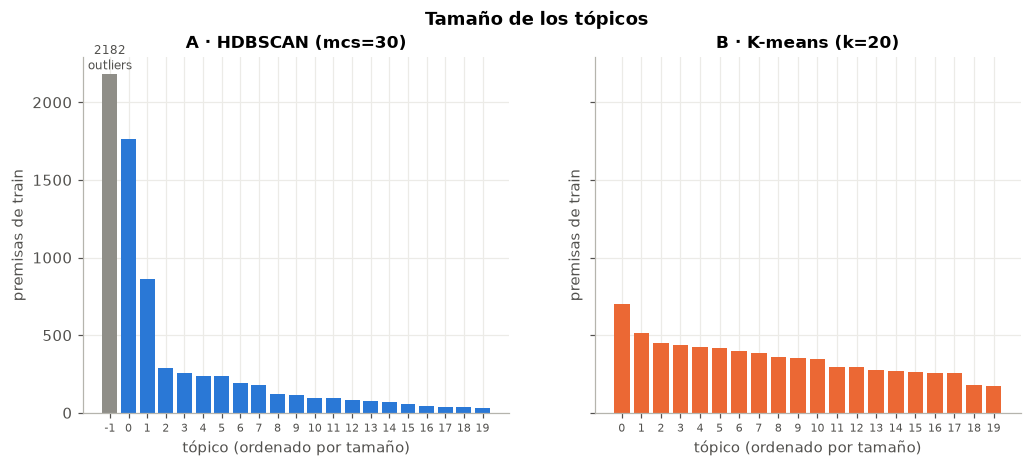

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, top, nombre, color in [(axes[0], top_hdb, f"A · HDBSCAN (mcs={MCS})", PALETA[0]), (axes[1], top_km, f"B · K-means (k={K})", PALETA[1])]:
    vc = pd.Series(top).value_counts()
    orden = ([-1] if -1 in vc.index else []) + [k for k in vc.index if k != -1]
    ax.bar(range(len(orden)), vc[orden].values, color=[GRIS if k == -1 else color for k in orden], width=0.8)
    ax.set_xticks(range(len(orden)), [str(k) for k in orden], fontsize=7)
    ax.set_title(nombre); ax.set_xlabel("tópico (ordenado por tamaño)"); ax.set_ylabel("premisas de train")
    if -1 in vc.index:
        ax.text(0, vc[-1] + 30, f"{vc[-1]}\noutliers", ha="center", fontsize=8, color="#52514e")
fig.suptitle("Tamaño de los tópicos", fontweight="bold"); fig.savefig(OUT / "fig_tamanos_topicos.png"); plt.show()

### 6.2. Palabras con más peso c-TF-IDF en los 8 tópicos más grandes

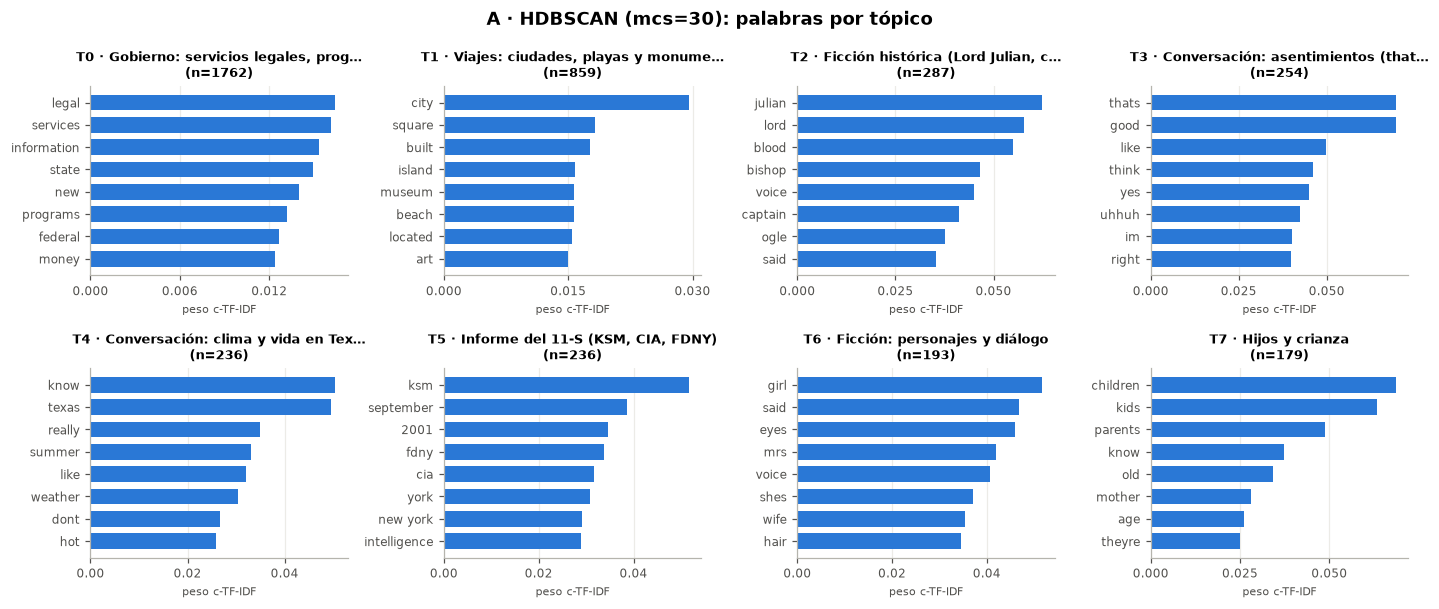

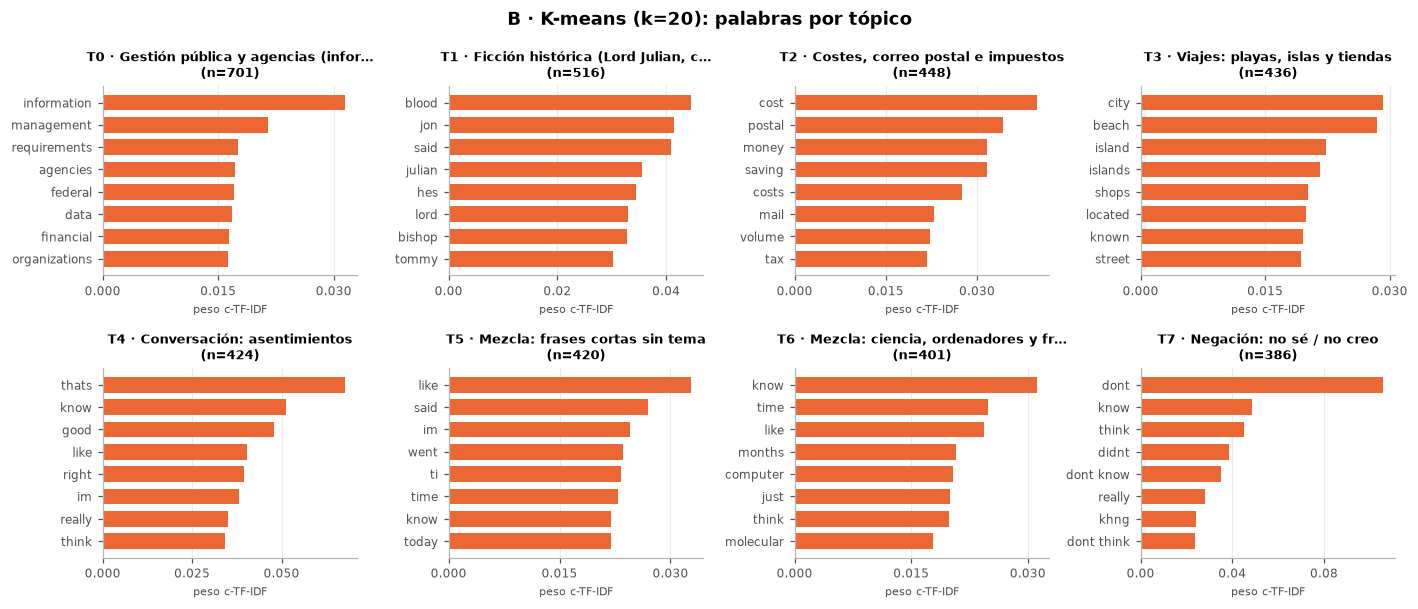

In [13]:
def barras_palabras(modelo, top, nombres, titulo, color, fichero, n=8, nw=8):
    vc = pd.Series(top).value_counts(); ks = [k for k in vc.index if k != -1][:n]
    fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
    for ax, k in zip(axes.flat, ks):
        pal = modelo.get_topic(k)[:nw][::-1]
        ax.barh([w for w, _ in pal], [s for _, s in pal], color=color, height=0.7)
        ax.set_title(f"T{k} · {corto(nombres[k], 34)}\n(n={vc[k]})", fontsize=8.5); ax.tick_params(labelsize=8); ax.grid(axis="y", visible=False)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
        ax.set_xlabel("peso c-TF-IDF", fontsize=7.5)
    fig.suptitle(titulo, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichero); plt.show()
barras_palabras(tm_hdb, top_hdb, NOMBRES_HDB, f"A · HDBSCAN (mcs={MCS}): palabras por tópico", PALETA[0], "fig_palabras_hdbscan.png")
barras_palabras(tm_km, top_km, NOMBRES_KM, f"B · K-means (k={K}): palabras por tópico", PALETA[1], "fig_palabras_kmeans.png")

### 6.3. Mapa 2D de los documentos

Para dibujar, se proyectan los embeddings de train a 2 dimensiones con UMAP (mismos parámetros, pero `n_components=2`). Esta proyección solo sirve para visualizar; el clustering se hizo en 5-D. Se colorean los 8 tópicos más grandes, con su número encima y su nombre en la leyenda (más de 8 colores ya no se distinguen bien); el resto de tópicos va en gris medio y los outliers en gris claro.

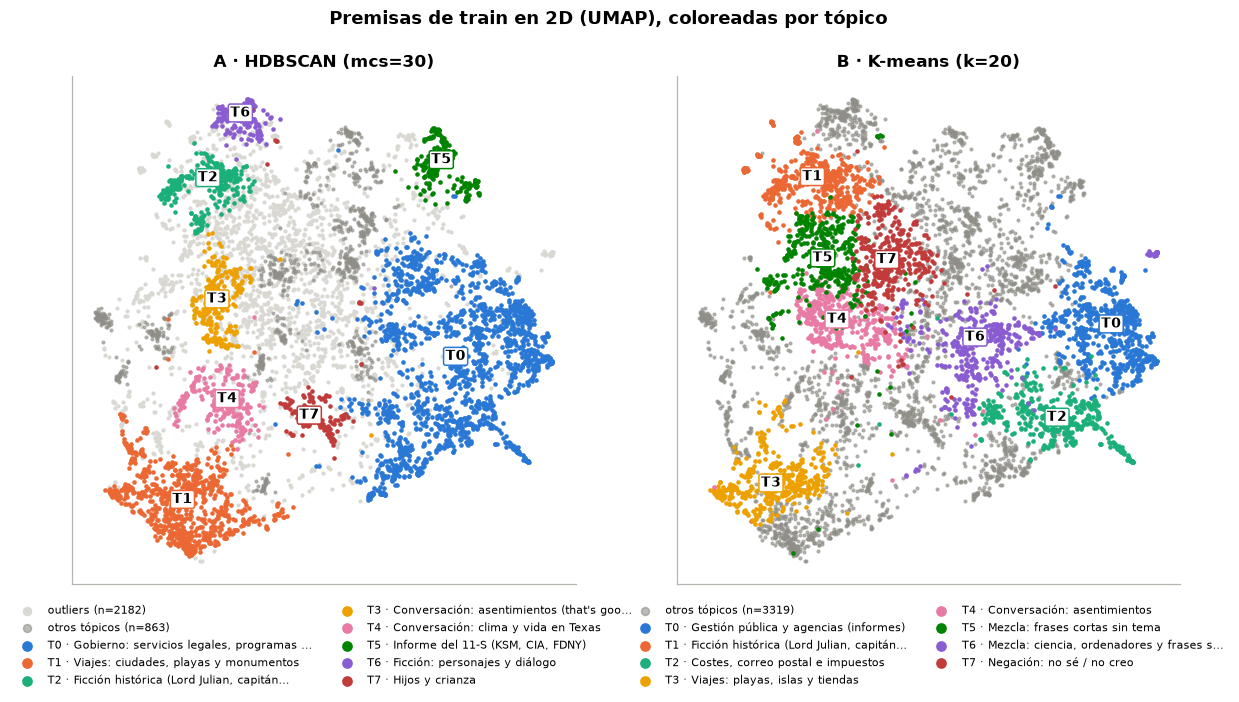

In [14]:
xy = UMAP(**{**UMAP_PARAMS, "n_components": 2}).fit_transform(E_tr)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, top, nombres, titulo in [(axes[0], top_hdb, NOMBRES_HDB, f"A · HDBSCAN (mcs={MCS})"), (axes[1], top_km, NOMBRES_KM, f"B · K-means (k={K})")]:
    vc = pd.Series(top).value_counts(); grandes = [k for k in vc.index if k != -1][:8]
    out = top == -1; resto = ~np.isin(top, grandes) & ~out
    ax.scatter(*xy[out].T, s=3, c=GRIS_CLARO, label=f"outliers (n={out.sum()})" if out.any() else None, rasterized=True)
    ax.scatter(*xy[resto].T, s=3, c=GRIS, alpha=0.6, label=f"otros tópicos (n={resto.sum()})", rasterized=True)
    for color, k in zip(PALETA, grandes):
        sel = top == k
        ax.scatter(*xy[sel].T, s=4, c=color, label=f"T{k} · {corto(nombres[k], 40)}", rasterized=True)
        cx, cy = np.median(xy[sel], axis=0)
        ax.text(cx, cy, f"T{k}", fontsize=9, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color, lw=1))
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=7.5, markerscale=3)
fig.suptitle("Premisas de train en 2D (UMAP), coloreadas por tópico", fontweight="bold")
fig.savefig(OUT / "fig_mapa_2d.png"); plt.show()

### 6.4. Comparación de los dos pipelines

| Aspecto | A · HDBSCAN | B · K-means |
|---|---|---|
| Número de tópicos | Lo decide el algoritmo (20 con mcs=30) | Lo fija el usuario (k=20) |
| Outliers | ~31 % en −1 | 0 %: todo documento recibe un tópico |
| Tamaños | Muy desiguales (de 34 a 1.762; mediana 107) | Más parecidos entre sí (de 171 a 701; mediana 350) |
| Diversidad de palabras (top-10) | 0,895: los tópicos comparten pocas palabras | 0,820: más repetición (*know, like, think* en varios clústeres conversacionales) |
| Interpretabilidad | Tópicos pequeños muy nítidos; un tópico "gobierno" demasiado grande | Gobierno bien partido en 4; aparecen 2–3 clústeres "cajón de sastre" |
| Estabilidad | Los temas con léxico propio (11-S, ficción histórica, texto sin traducir, lengua) salen en ambos | |
| Idioma (NMI) | ≈0,03: agrupa por tema | ≈0,02–0,03: agrupa por tema |

Conclusión: A es mejor para interpretar, porque separa lo que no encaja en lugar de mezclarlo. B es mejor si se necesita asignar un tópico a todo (por ejemplo, como feature), aunque algunos tópicos pierdan sentido.

## 7. Tópico de cada fila de train y val (`transform`)

- **Filas de train:** heredan el tópico que recibió su premisa al ajustar (`fit`) el modelo con las 7.051 premisas de train.
- **Filas de val:** todas las premisas de val (2.250) pasan por `transform`, como haría el modelo con datos nuevos. `transform` lleva el embedding al UMAP ya ajustado y después a HDBSCAN (`approximate_predict`) o a K-means (`predict`, el centro más cercano). Nada se reajusta con val, así que no hay fuga.
- Esto incluye las 1.092 premisas de val que también están en train: no se copia su tópico del `fit`, sino que se vuelven a pasar por `transform`. Así se cumple literalmente "ajustar con train y transformar val". Además, sirve de control de consistencia: se mide en cuántas de esas premisas `transform` devuelve el mismo tópico que el `fit`.

In [15]:
val_p = premises[premises.in_val].reset_index(drop=True)
E_v = emb[premises.in_val.values]
t0 = time.perf_counter()
tv_hdb = np.asarray(tm_hdb.transform(val_p.text.tolist(), E_v)[0])
tv_km = np.asarray(tm_km.transform(val_p.text.tolist(), E_v)[0])
print(f"transform de {len(val_p)} premisas de val: {time.perf_counter() - t0:.1f} s")
mapa_tr = pd.DataFrame({"premise": tr.premise_original, "topic_hdb": top_hdb, "topic_km": top_km})
mapa_va = pd.DataFrame({"premise": val_p.premise_original, "topic_hdb": tv_hdb, "topic_km": tv_km})
base = df[["id", "part", "premise", "label", "lang_abv"]]
rows = pd.concat([base[base.part == "train"].merge(mapa_tr, on="premise", how="left", validate="many_to_one"),
                  base[base.part == "val"].merge(mapa_va, on="premise", how="left", validate="many_to_one")])
rows = rows.set_index("id").loc[df.id].reset_index()
assert rows[["topic_hdb", "topic_km"]].notna().all().all() and len(rows) == 12120
rows[["topic_hdb", "topic_km"]] = rows[["topic_hdb", "topic_km"]].astype(int)
rows[["id", "part", "topic_hdb", "topic_km"]].to_csv(OUT / "topics_rows.csv", index=False)
print("Guardado", OUT / "topics_rows.csv")

# Control de consistencia: premisas que están en train y en val.
comp = mapa_va.merge(mapa_tr, on="premise", suffixes=("_transform", "_fit"))
print(f"Premisas compartidas: {len(comp)} | mismo tópico con transform que con fit: "
      f"HDBSCAN {np.mean(comp.topic_hdb_transform == comp.topic_hdb_fit):.1%} · "
      f"K-means {np.mean(comp.topic_km_transform == comp.topic_km_fit):.1%}")
print(f"% outliers HDBSCAN: premisas de train (fit) {np.mean(top_hdb == -1):.1%} | premisas de val (transform) {np.mean(tv_hdb == -1):.1%}")
display(pd.crosstab(rows.part, rows.topic_hdb.eq(-1).map({True: "outlier", False: "con tópico"})))

transform de 2250 premisas de val: 3.0 s
Guardado results_topics\topics_rows.csv
Premisas compartidas: 1092 | mismo tópico con transform que con fit: HDBSCAN 94.1% · K-means 96.7%
% outliers HDBSCAN: premisas de train (fit) 30.9% | premisas de val (transform) 34.9%


topic_hdb,con tópico,outlier
part,,
train,6702,2994
val,1584,840


## 8. Tópicos frente a clases NLI

Recordatorio: los tópicos describen de qué habla la premisa (contenido). No son las clases NLI. La clase (entailment, neutral, contradiction) depende de la relación entre premisa e hipótesis, y cada premisa aparece con hipótesis de distintas clases. Por eso cabe esperar que los tópicos estén poco asociados con la clase.

Se cruza el tópico de cada fila de train (9.696 pares) con su etiqueta: recuentos, proporciones, chi-cuadrado (¿la distribución de clases es la misma en todos los tópicos?) y V de Cramér (fuerza de la asociación: 0 = ninguna, 1 = total). Con 3 clases, V < 0,1 es una asociación despreciable.

*Nota:* las filas de una misma premisa comparten tópico y no son del todo independientes, así que el p-valor del chi-cuadrado es algo optimista. La V de Cramér, como medida de tamaño del efecto, es lo importante.

In [16]:
from scipy.stats import chi2_contingency
rtr = rows[rows.part == "train"].assign(clase=lambda d: d.label.map(LABELS))
def topicos_vs_clase(col, nombres):
    ct = pd.crosstab(rtr[col], rtr.clase).reindex(columns=list(LABELS.values()))
    chi2, p, dof, esperado = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    prop = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
    tabla = pd.concat([ct.sum(axis=1).rename("n"), prop.add_suffix(" %")], axis=1)
    tabla.insert(0, "nombre", [nombres[k] for k in tabla.index])
    return tabla, {"chi2": round(chi2, 1), "gl": dof, "p": p, "V_Cramer": round(v, 3), "celdas_esperado<5": int((esperado < 5).sum())}
tc_hdb, est_hdb = topicos_vs_clase("topic_hdb", NOMBRES_HDB)
tc_km, est_km = topicos_vs_clase("topic_km", NOMBRES_KM)
print("A · HDBSCAN:", est_hdb); display(tc_hdb)
print("B · K-means:", est_km); display(tc_km)
pd.DataFrame([{"configuracion": "A · HDBSCAN", **est_hdb}, {"configuracion": "B · K-means", **est_km}]).to_csv(OUT / "topicos_vs_clase_estadisticos.csv", index=False)
tc_hdb.to_csv(OUT / "topicos_vs_clase_hdbscan.csv"); tc_km.to_csv(OUT / "topicos_vs_clase_kmeans.csv")

A · HDBSCAN: {'chi2': np.float64(40.0), 'gl': 40, 'p': np.float64(0.46860705833676325), 'V_Cramer': np.float64(0.045), 'celdas_esperado<5': 0}


,nombre,n,entailment %,neutral %,contradiction %
topic_hdb,,,,,
-1,Outliers (sin tópico),2994,33.9,32.3,33.8
0,"Gobierno: servicios legales, programas y costes",2423,34.8,32.4,32.8
1,"Viajes: ciudades, playas y monumentos",1267,36.7,31.1,32.2
2,"Ficción histórica (Lord Julian, capitán Blood)",382,31.7,32.7,35.6
3,"Conversación: asentimientos (that's good, yes)",371,37.7,28.8,33.4
4,Conversación: clima y vida en Texas,334,36.5,28.1,35.3
5,"Informe del 11-S (KSM, CIA, FDNY)",265,33.6,32.5,34.0
6,Ficción: personajes y diálogo,268,32.8,32.1,35.1
7,Hijos y crianza,239,31.4,34.7,33.9


B · K-means: {'chi2': np.float64(30.3), 'gl': 38, 'p': np.float64(0.8073876911780052), 'V_Cramer': np.float64(0.04), 'celdas_esperado<5': 0}


,nombre,n,entailment %,neutral %,contradiction %
topic_km,,,,,
0,Gestión pública y agencias (informes),994,37.5,29.9,32.6
1,"Ficción histórica (Lord Julian, capitán Blood)",758,34.0,32.3,33.6
2,"Costes, correo postal e impuestos",650,35.4,31.2,33.4
3,"Viajes: playas, islas y tiendas",633,35.7,31.1,33.2
4,Conversación: asentimientos,639,36.5,30.4,33.2
5,Mezcla: frases cortas sin tema,568,32.0,32.9,35.0
6,"Mezcla: ciencia, ordenadores y frases sueltas",504,31.3,33.5,35.1
7,Negación: no sé / no creo,538,32.0,32.5,35.5
8,"Monumentos: templos, iglesias, historia",558,36.7,32.4,30.8


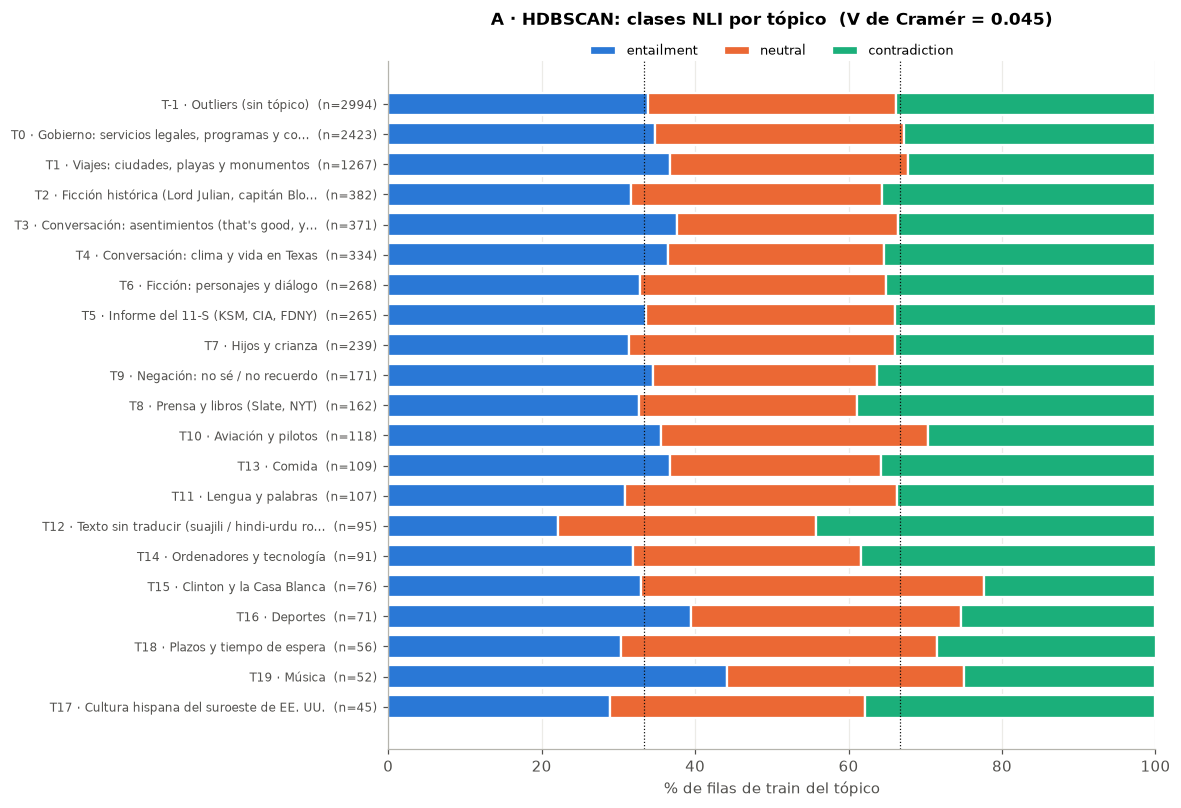

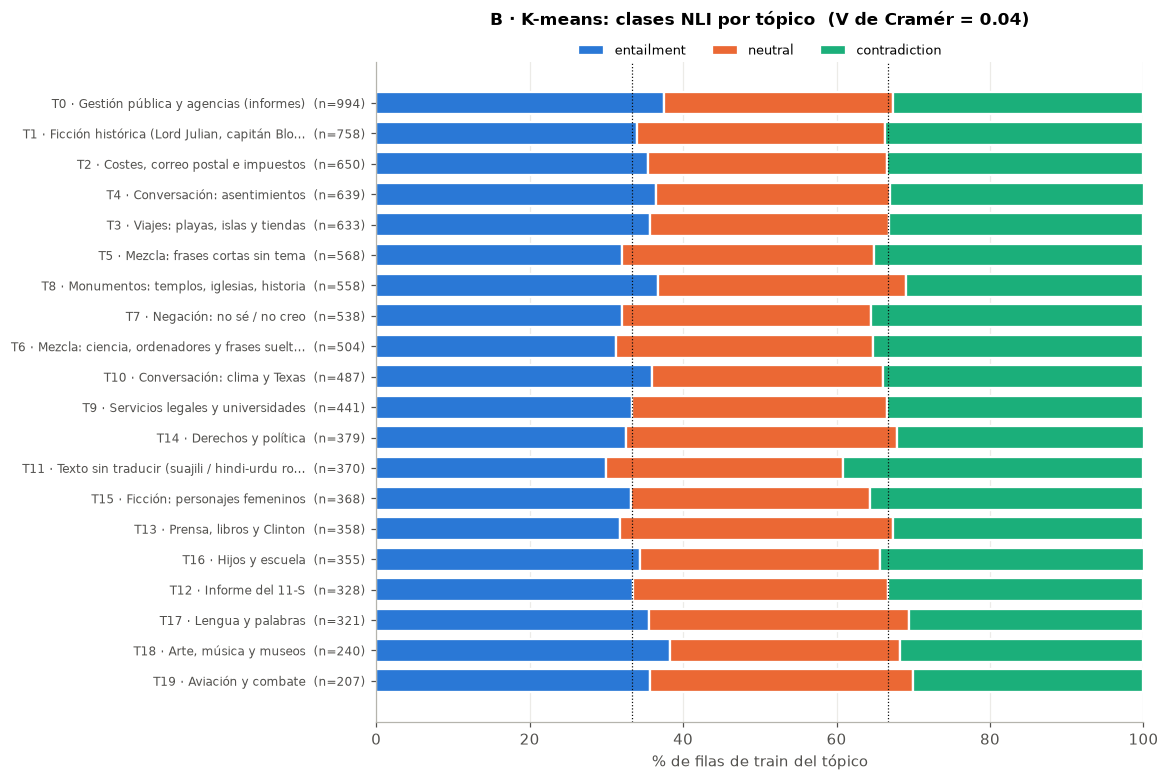

In [17]:
def barra_apilada(tabla, titulo, fichero):
    t = tabla.sort_values("n", ascending=True)
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(t) + 1.4))
    izq = np.zeros(len(t))
    for clase in LABELS.values():
        v = t[f"{clase} %"].values
        ax.barh(range(len(t)), v, left=izq, color=COLOR_CLASE[clase], edgecolor="white", linewidth=1.5, height=0.75, label=clase)
        izq += v
    ax.set_yticks(range(len(t)), [f"T{k} · {corto(nm, 44)}  (n={n})" for k, nm, n in zip(t.index, t.nombre, t.n)], fontsize=8)
    ax.axvline(100 / 3, color="#0b0b0b", lw=0.8, ls=":"); ax.axvline(200 / 3, color="#0b0b0b", lw=0.8, ls=":")
    ax.set_xlim(0, 100); ax.set_xlabel("% de filas de train del tópico"); ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0 + 0.9 / len(t)), ncol=3, fontsize=8.5)
    ax.set_title(titulo, pad=24); fig.savefig(OUT / fichero); plt.show()
barra_apilada(tc_hdb, f"A · HDBSCAN: clases NLI por tópico  (V de Cramér = {est_hdb['V_Cramer']})", "fig_clases_por_topico_hdbscan.png")
barra_apilada(tc_km, f"B · K-means: clases NLI por tópico  (V de Cramér = {est_km['V_Cramer']})", "fig_clases_por_topico_kmeans.png")

Lectura. Las barras están casi todas cerca del reparto global (~34/32/34 %, líneas de puntos en 1/3 y 2/3).
- **A · HDBSCAN:** χ² = 40,0 con 40 g.l., p = 0,47, V de Cramér = 0,045.
- **B · K-means:** χ² = 30,3 con 38 g.l., p = 0,81, V = 0,040.

Ni siquiera se puede rechazar que la distribución de clases sea la misma en todos los tópicos, y la fuerza de la asociación es despreciable. El tópico no determina la clase. Las desviaciones visibles están en tópicos pequeños, donde unas decenas de filas mueven mucho el porcentaje (por eso se muestra siempre el *n*). Por ejemplo, *Clinton* (n=76) tiene un 45 % de neutral y *Texto sin traducir* (n=95) un 44 % de contradiction, pero con estos tamaños son compatibles con el azar. Es lo esperado en un dataset NLI bien construido: para cada premisa los anotadores escribieron una hipótesis de cada clase, así que el tema de la premisa no puede predecir la clase. Por eso, en el experimento (`topic_experiment.ipynb`), no cabe esperar una mejora grande al añadir el tópico como feature.

## 9. ¿Agrupan los tópicos por idioma o por tema?

El corpus original es multilingüe (15 idiomas). Hay que comprobar que los clústeres no son simplemente "los textos en chino", "los textos en árabe"… Se mide a nivel de documento (premisas de train):
- **NMI(tópico, idioma):** 0 si son independientes.
- **Pureza de idioma por tópico:** % del idioma más frecuente en el tópico. Hay que compararla con la proporción global de inglés (~43 % de las premisas de train). Una pureza parecida significa que el tópico no está dominado por un idioma.
- **Control:** se repite el mismo UMAP + clustering con los embeddings del texto original sin traducir, para ver si la traducción es lo que evita agrupar por idioma.

In [18]:
base_en = np.mean(lang_tr == "en")
def pureza(top, nombres):
    d = pd.DataFrame({"topic": top, "lang": lang_tr})
    f = d.groupby("topic").lang.agg(n="size", idioma_top=lambda s: s.value_counts().index[0],
                                     pureza=lambda s: round(100 * s.value_counts(normalize=True).iloc[0], 1),
                                     pct_ingles=lambda s: round(100 * s.eq("en").mean(), 1))
    f.insert(0, "nombre", [nombres[k] for k in f.index]); return f
pur_hdb, pur_km = pureza(top_hdb, NOMBRES_HDB), pureza(top_km, NOMBRES_KM)
print(f"Proporción global de inglés en las premisas de train: {base_en:.1%}")
print("A · HDBSCAN"); display(pur_hdb)
print("B · K-means"); display(pur_km)

Proporción global de inglés en las premisas de train: 43.2%
A · HDBSCAN


,nombre,n,idioma_top,pureza,pct_ingles
topic,,,,,
-1,Outliers (sin tópico),2182,en,43.4,43.4
0,"Gobierno: servicios legales, programas y costes",1762,en,45.1,45.1
1,"Viajes: ciudades, playas y monumentos",859,en,55.1,55.1
2,"Ficción histórica (Lord Julian, capitán Blood)",287,en,36.9,36.9
3,"Conversación: asentimientos (that's good, yes)",254,en,48.8,48.8
4,Conversación: clima y vida en Texas,236,en,50.4,50.4
5,"Informe del 11-S (KSM, CIA, FDNY)",236,en,9.3,9.3
6,Ficción: personajes y diálogo,193,en,50.3,50.3
7,Hijos y crianza,179,en,36.9,36.9


B · K-means


,nombre,n,idioma_top,pureza,pct_ingles
topic,,,,,
0,Gestión pública y agencias (informes),701,en,52.5,52.5
1,"Ficción histórica (Lord Julian, capitán Blood)",516,en,51.7,51.7
2,"Costes, correo postal e impuestos",448,en,54.5,54.5
3,"Viajes: playas, islas y tiendas",436,en,53.0,53.0
4,Conversación: asentimientos,424,en,58.3,58.3
5,Mezcla: frases cortas sin tema,420,en,39.8,39.8
6,"Mezcla: ciencia, ordenadores y frases sueltas",401,en,32.9,32.9
7,Negación: no sé / no creo,386,en,41.7,41.7
8,"Monumentos: templos, iglesias, historia",360,en,61.9,61.9


In [19]:
# Control: mismo pipeline con embeddings del texto ORIGINAL (sin traducir).
E_tr_orig = emb_orig[premises.in_train.values]
red_orig = UMAP(**UMAP_PARAMS).fit_transform(E_tr_orig)
lab_hdb_o = HDBSCAN(min_cluster_size=MCS).fit_predict(red_orig)
lab_km_o = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(red_orig)
idioma = pd.DataFrame([
    {"texto": "traducido (TEXT_COL)", "clustering": f"HDBSCAN mcs={MCS}", "n_topicos": len(set(top_hdb) - {-1}), "NMI_idioma": NMI(lang_tr, top_hdb)},
    {"texto": "traducido (TEXT_COL)", "clustering": f"K-means k={K}", "n_topicos": K, "NMI_idioma": NMI(lang_tr, top_km)},
    {"texto": "original (control)", "clustering": f"HDBSCAN mcs={MCS}", "n_topicos": len(set(lab_hdb_o) - {-1}), "NMI_idioma": NMI(lang_tr, lab_hdb_o)},
    {"texto": "original (control)", "clustering": f"K-means k={K}", "n_topicos": K, "NMI_idioma": NMI(lang_tr, lab_km_o)},
]).round(3)
idioma.to_csv(OUT / "topicos_vs_idioma_nmi.csv", index=False); display(idioma)

,texto,clustering,n_topicos,NMI_idioma
0,traducido (TEXT_COL),HDBSCAN mcs=30,20,0.026
1,traducido (TEXT_COL),K-means k=20,20,0.021
2,original (control),HDBSCAN mcs=30,32,0.065
3,original (control),K-means k=20,20,0.048


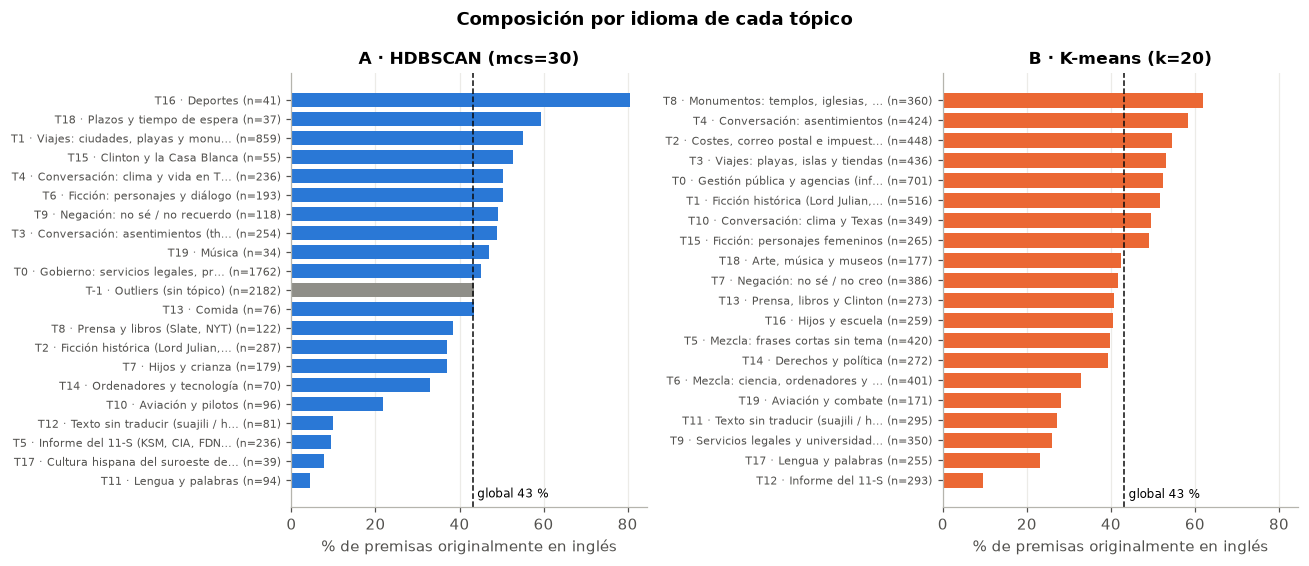

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
for ax, pur, titulo, color in [(axes[0], pur_hdb, f"A · HDBSCAN (mcs={MCS})", PALETA[0]), (axes[1], pur_km, f"B · K-means (k={K})", PALETA[1])]:
    p = pur.sort_values("pct_ingles")
    ax.barh(range(len(p)), p.pct_ingles, color=[GRIS if k == -1 else color for k in p.index], height=0.75)
    ax.set_yticks(range(len(p)), [f"T{k} · {corto(nm, 32)} (n={n})" for k, nm, n in zip(p.index, p.nombre, p.n)], fontsize=7.5)
    ax.axvline(100 * base_en, color="#0b0b0b", lw=1, ls="--")
    ax.text(100 * base_en + 1, -0.9, f"global {100*base_en:.0f} %", fontsize=8)
    ax.set_xlabel("% de premisas originalmente en inglés"); ax.set_title(titulo); ax.grid(axis="y", visible=False)
fig.suptitle("Composición por idioma de cada tópico", fontweight="bold"); fig.tight_layout()
fig.savefig(OUT / "fig_idioma_por_topico.png"); plt.show()

Lectura.
- Con el texto traducido, la NMI entre tópico e idioma es muy baja (0,026 en A y 0,021 en B): los tópicos agrupan por tema. En ningún tópico un idioma no inglés supera el 40 % de los documentos. La "pureza" más alta casi siempre corresponde al inglés, que es el idioma mayoritario (43 % de las premisas).
- El % de inglés sí varía entre tópicos (del ~5 % al ~80 %), pero por cómo se construyó el dataset y no porque el algoritmo separe idiomas. Las premisas inglesas y las de los otros 14 idiomas no vienen de los mismos documentos fuente. Por ejemplo, el *informe del 11-S* tiene solo un 9 % de premisas inglesas y *Deportes* (n=41) un 80 %. El tópico "texto sin traducir" es la excepción esperada: casi no tiene inglés y lo domina el suajili, por las premisas que no se tradujeron.
- **Control con el texto original:** la NMI con el idioma sube a 0,065 (HDBSCAN) y 0,048 (K-means), más o menos el doble, pero sigue siendo baja. El modelo de embeddings es multilingüe y acerca una frase a su traducción, así que incluso sin traducir MiniLM agrupa sobre todo por significado. La traducción reduce todavía más el efecto del idioma y, sobre todo, hace que c-TF-IDF dé palabras legibles en un solo idioma.

## 10. Conclusiones y tabla de resultados

In [21]:
display(comparacion.set_index("configuracion").T)
display(pd.DataFrame([{"configuracion": "A · HDBSCAN", **est_hdb}, {"configuracion": "B · K-means", **est_km}]).set_index("configuracion"))
print("Ficheros en results_topics/:", sorted(p.name for p in OUT.iterdir()))

configuracion,A · HDBSCAN mcs=30,B · K-means k=20
n_topicos,20.000,20.000
pct_outliers,30.900,0.000
tam_max,1762.000,701.000
tam_mediana,107.000,349.500
tam_min,34.000,171.000
diversidad_top10,0.895,0.820
NMI_idioma,0.026,0.021
NMI_idioma_sin_outliers,0.037,0.021
segundos,8.900,9.000


,chi2,gl,p,V_Cramer,celdas_esperado<5
configuracion,,,,,
A · HDBSCAN,40.0,40,0.468607,0.045,0
B · K-means,30.3,38,0.807388,0.040,0


Ficheros en results_topics/: ['RESUMEN_BLOQUE2.md', 'comparacion_pipelines.csv', 'eda_longitudes.png', 'errores_por_topico_hdb.csv', 'errores_por_topico_km.csv', 'experimento.csv', 'experimento_pruebas.csv', 'fig_clases_por_topico_hdbscan.png', 'fig_clases_por_topico_kmeans.png', 'fig_confusion_catboost.png', 'fig_confusion_naive_bayes.png', 'fig_errores_por_topico_catboost.png', 'fig_idioma_por_topico.png', 'fig_mapa_2d.png', 'fig_palabras_hdbscan.png', 'fig_palabras_kmeans.png', 'fig_roc_catboost.png', 'fig_roc_naive_bayes.png', 'fig_tamanos_topicos.png', 'topicos_hdbscan.csv', 'topicos_kmeans.csv', 'topicos_vs_clase_estadisticos.csv', 'topicos_vs_clase_hdbscan.csv', 'topicos_vs_clase_kmeans.csv', 'topicos_vs_idioma_nmi.csv', 'topics_rows.csv', 'val_premise_seen.csv']


- **Corpus y documentos:** 7.051 premisas de train, sin repetir, con texto traducido. Las 2.250 premisas de val (incluidas las que también están en train) reciben su tópico con `transform`.
- **A · HDBSCAN (mcs=30):** 20 tópicos y 31 % de outliers. Tópicos pequeños muy nítidos (11-S, ficción histórica, Clinton, música, deportes) y un tópico "gobierno" demasiado grande.
- **B · K-means (k=20):** sin outliers y con tamaños más equilibrados. Parte bien el bloque del gobierno, pero crea 2–3 clústeres "cajón de sastre" sin tema.
- **Los tópicos son los géneros de MultiNLI** (gobierno, viajes, ficción, teléfono, Slate, 11-S), lo que confirma el origen XNLI/MultiNLI de los datos.
- **Clases NLI:** asociación despreciable (V de Cramér pequeña): el tema de la premisa no predice la relación premisa–hipótesis.
- **Idioma:** NMI ≈ 0,03, así que los tópicos agrupan por tema y no por idioma. La única excepción es un tópico de texto que se quedó sin traducir.
- **Para el experimento** se usan las dos configuraciones como features one-hot. Para K-means (sin −1) la codificación es más limpia. Para HDBSCAN el −1 es una categoría propia.